In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import linkage, dendrogram

In [2]:
wine = load_wine(as_frame=True)

df = wine.frame.copy()

# Remove the original target label for unsupervised clustering
X = df.drop(columns=["target"])

print("Dataset shape:", X.shape)
print("\nFirst five rows:")
display(X.head())

print("\nMissing values:")
print(X.isnull().sum().sum())

print("\nDataset information:")
X.info()

Dataset shape: (178, 13)

First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Missing values:
0

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 

In [3]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)

Original shape: (178, 13)
Scaled shape: (178, 13)


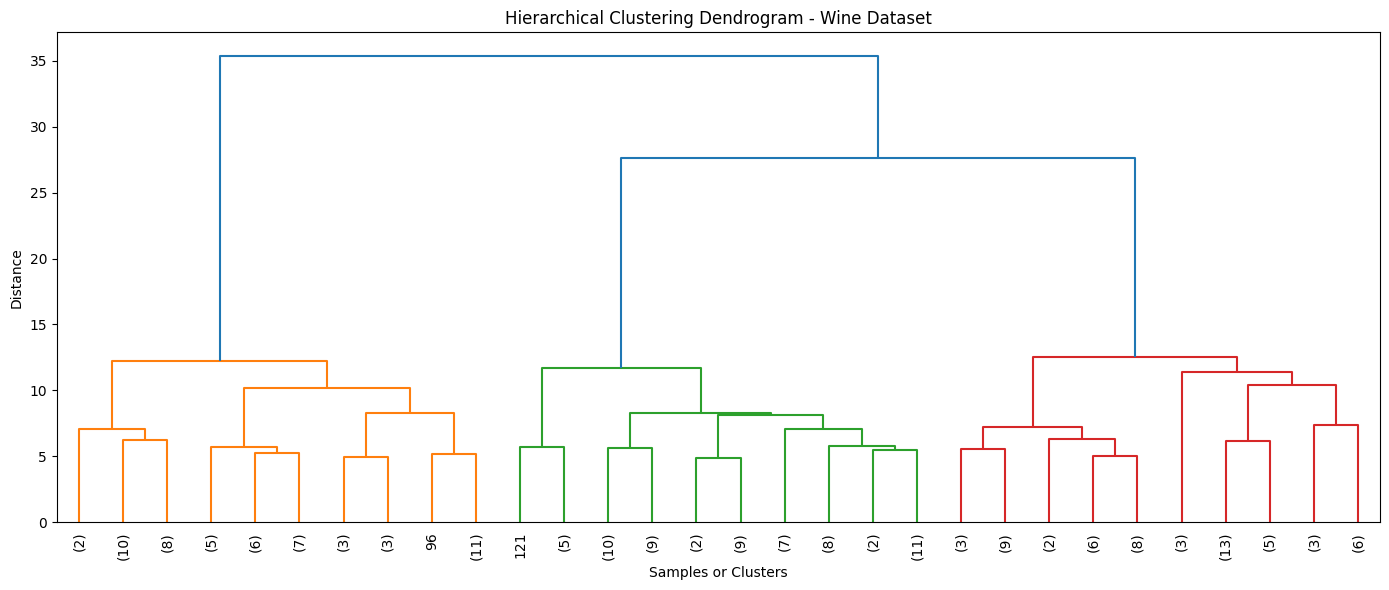

In [4]:
# Calculate hierarchical linkage
Z = linkage(X_scaled, method="ward")

# Plot the dendrogram
plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram - Wine Dataset")
plt.xlabel("Samples or Clusters")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

In [5]:
hac = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

clusters = hac.fit_predict(X_scaled)

df["Cluster"] = clusters

print("Cluster labels:")
print(clusters)

print("\nNumber of samples in each cluster:")
print(df["Cluster"].value_counts().sort_index())

Cluster labels:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 1 1 0 0 0 2 2 0 1 0 1 2 0 2
 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 2 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Number of samples in each cluster:
Cluster
0    58
1    56
2    64
Name: count, dtype: int64


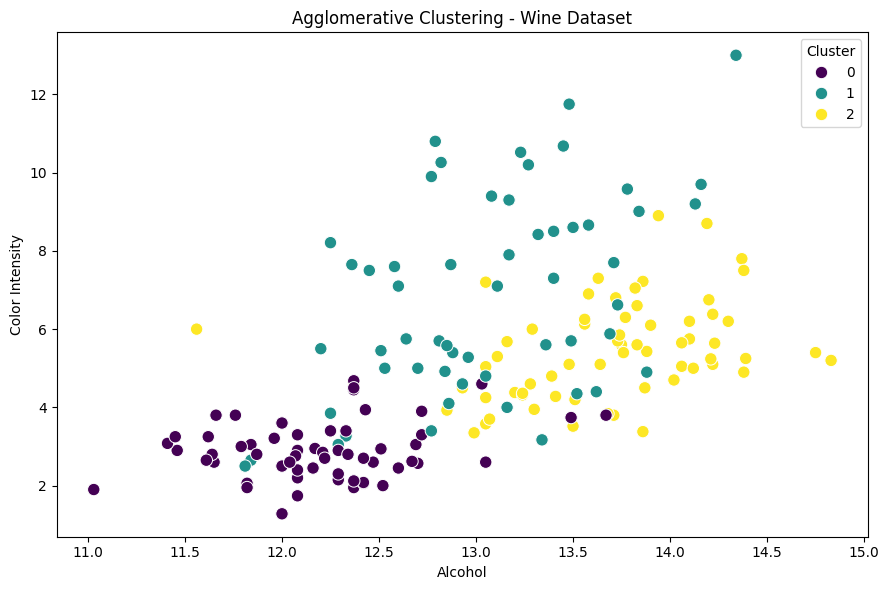

In [6]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="alcohol",
    y="color_intensity",
    hue="Cluster",
    palette="viridis",
    s=80
)

plt.title("Agglomerative Clustering - Wine Dataset")
plt.xlabel("Alcohol")
plt.ylabel("Color Intensity")
plt.tight_layout()
plt.show()

In [7]:
score = silhouette_score(X_scaled, clusters)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.2774


In [8]:
methods = ["ward", "complete", "average", "single"]

results = []

for method in methods:
    model = AgglomerativeClustering(
        n_clusters=3,
        linkage=method
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    results.append({
        "Linkage Method": method,
        "Number of Clusters": len(np.unique(labels)),
        "Silhouette Score": round(score, 4)
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="Silhouette Score",
        ascending=False
    )
)

,Linkage Method,Number of Clusters,Silhouette Score
0,ward,3,0.2774
1,complete,3,0.2038
3,single,3,0.1827
2,average,3,0.1575


In [9]:
cluster_summary = df.groupby("Cluster")[[
    "alcohol",
    "malic_acid",
    "flavanoids",
    "color_intensity",
    "proline"
]].mean().round(2)

display(cluster_summary)

,alcohol,malic_acid,flavanoids,color_intensity,proline
Cluster,,,,,
0,12.20,1.94,2.09,2.90,501.43
1,13.06,3.17,0.85,6.85,624.95
2,13.67,1.97,3.01,5.45,1076.05
